# Age Estimation and Gender Classification

In this assignment, you will train CNN models to estimate a person's age and predict their gender based on face images. Please read carefully all the instructions before you start to write your code.

**Your Tasks**

You are supposed to train two CNN models.
- Model A: Train a CNN model from scratch, following a few restrictions. Save this model as `age_gender_A.keras`
- Model B: Fine-tune a pre-trained model to perform the same task. Save this model as `age_gender_B.keras`

**Dataset**

Your models will be trained and validated on a folder `train_val/` containing 5,000 labeled face images (size: 128 x 128), originated from the UTKFace dataset. During the assessment phase, your code will be tested on unseen test data.

**Performance Metric**

The evaluation of your models on the test set will be based on the following metrics:
- age estimation: - Mean Absolute Error (MAE)
- gender prediction: accuracy

**GPU Time Management**

Please use the available GPU time wisely, as there are some limitations on free GPU usage. It is said the users can use up to 12 hours in row in Google Colab. But many people found they reached its limit far less than 12 hours. To minimize the risk of reaching the limit, consider the following suggestions:
1. Ensure you have a stable internet connection.
2. Carefully validate your hyperparameters before starting the training process.
3. Based on past experience, each model should be trained in less than 2 hours. If the training time is significantly longer, you may need to adjust your model architecture.


## Setting Up: Mount the google drive
Mount your google drive to the notebook. Also don't forget to **enable GPU** before your training.


In [11]:
#
# Add your code here
#

## Visualize a few photos
It's always beneficial to thoroughly understand your data before beginning the training process. To get a first-hand impression of the dataset, please display a minimum of 20 images from the `train_val/` folder, along with their corresponding age and gender labels. This will help you gain initial insights into the dataset.

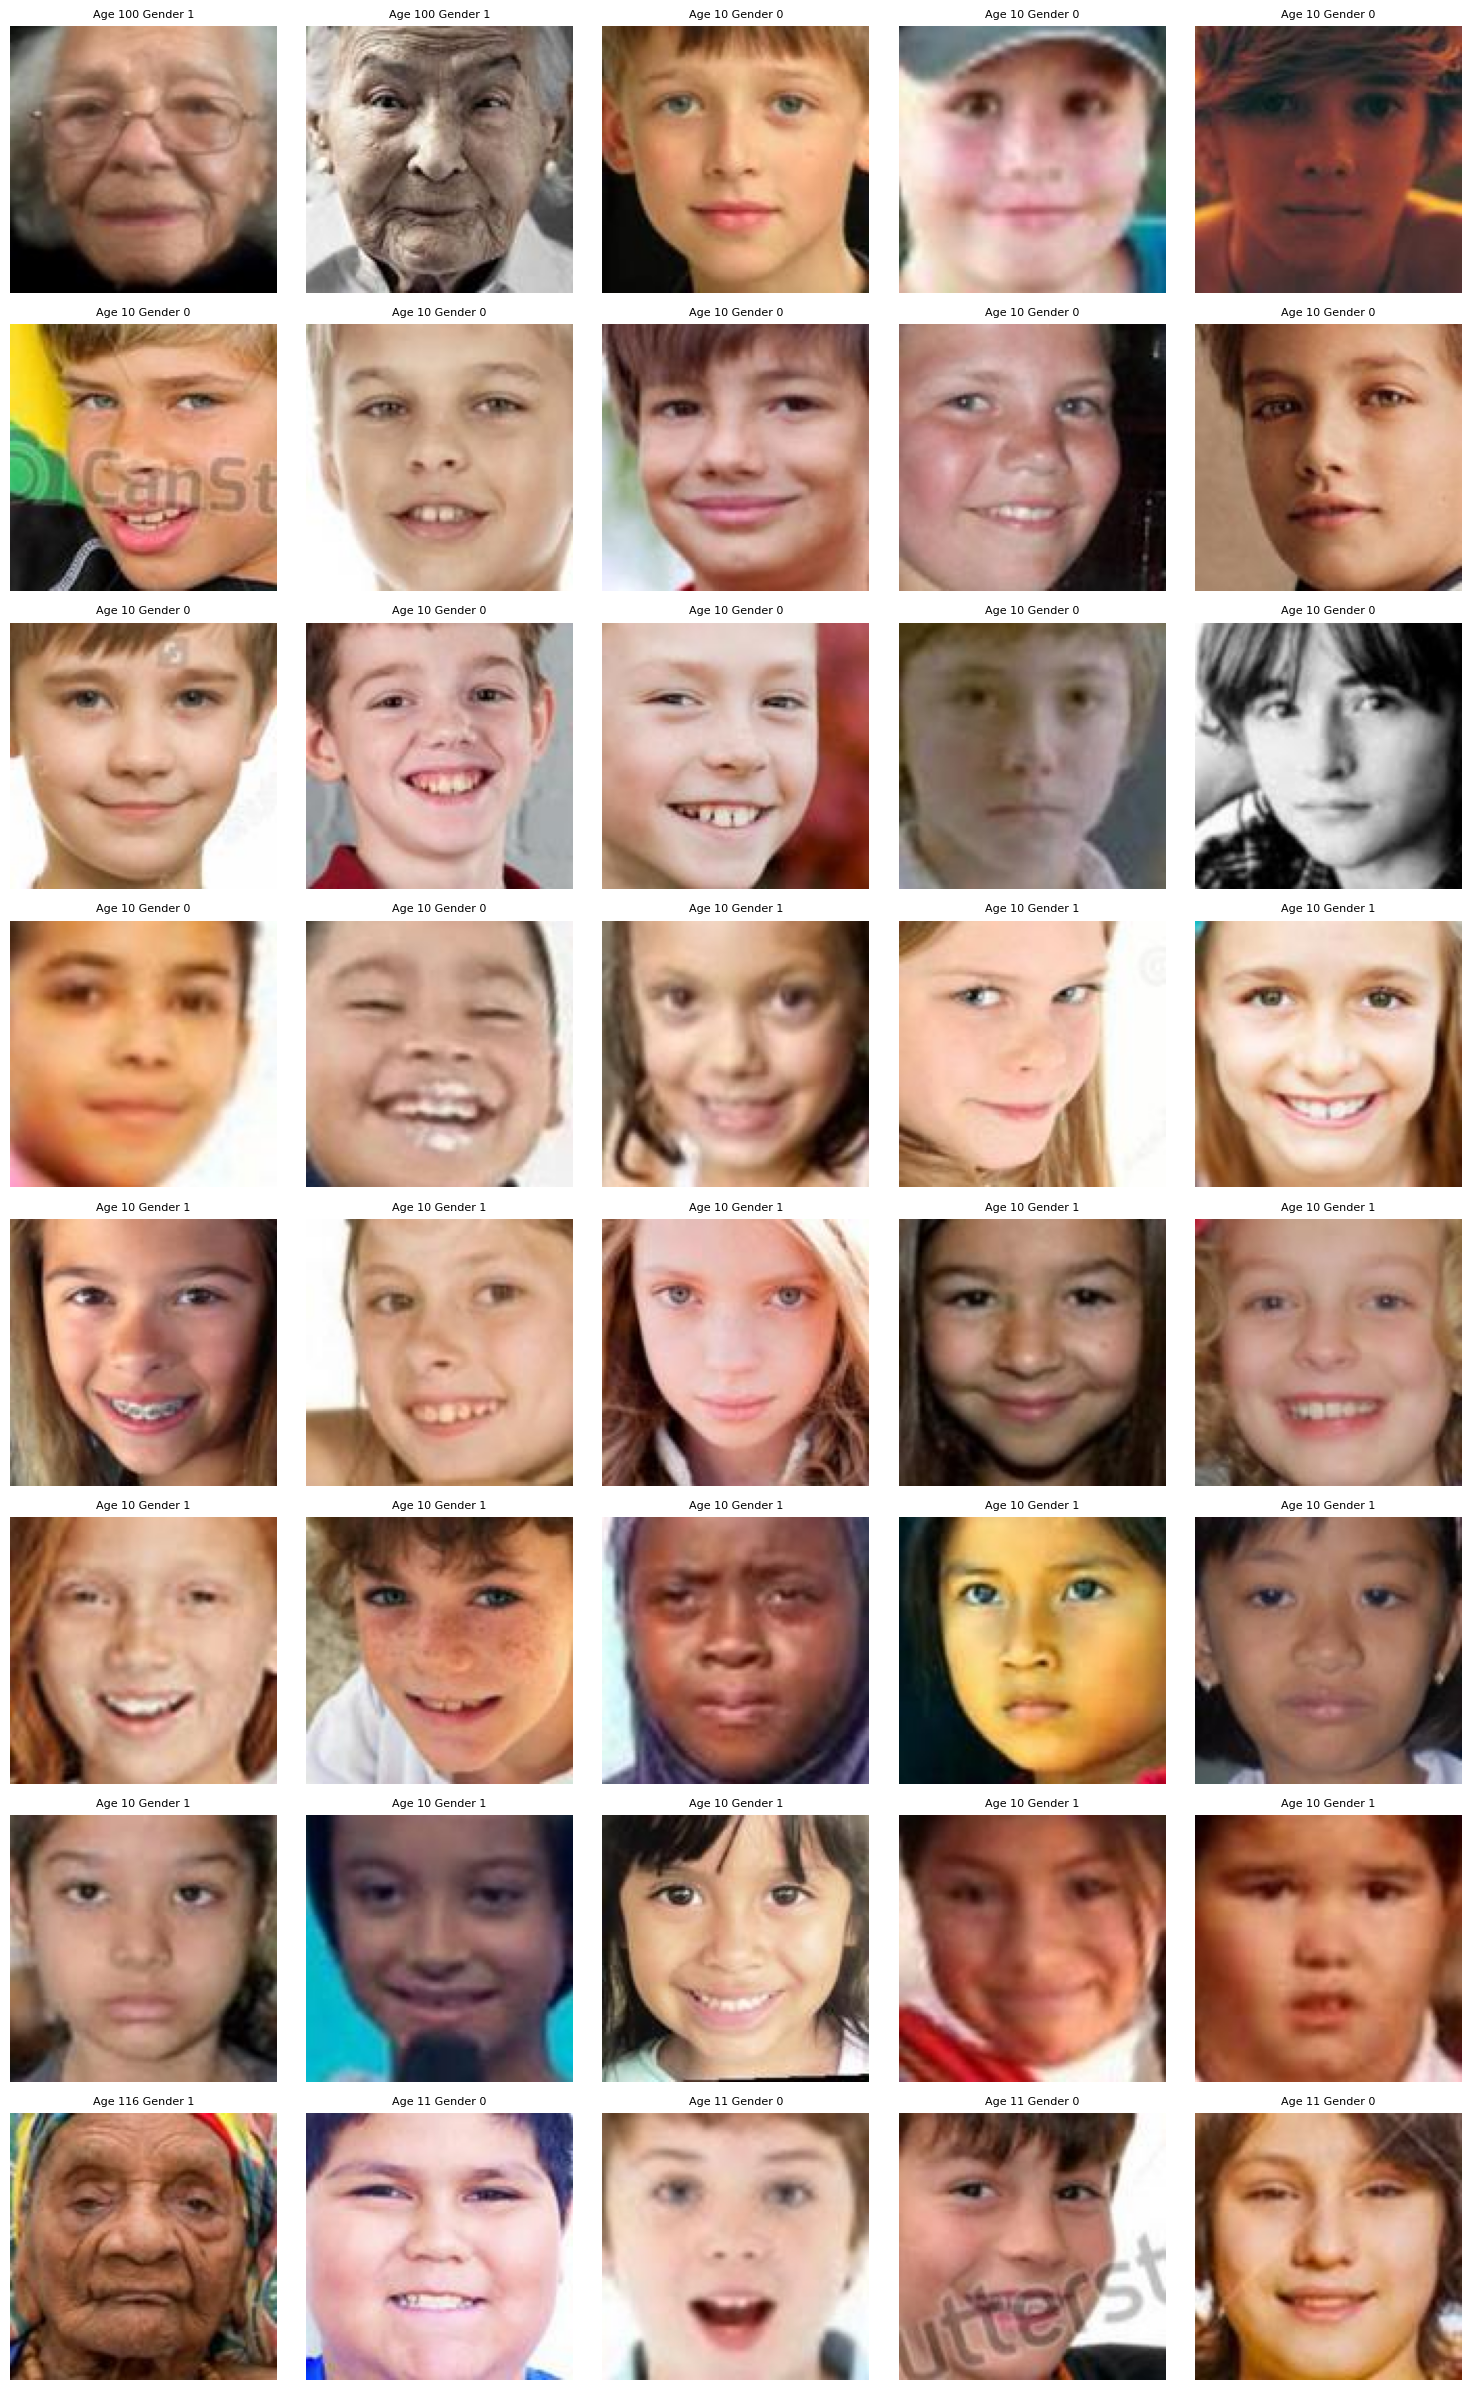

In [12]:
#
# Add your code here
#


import os
import math
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Folder path
folder = "train_val"

# Get all image files ending with .jpg (sorted)
image_paths = sorted(
    [os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith('.jpg')]
)

# Limit to first 40 images (optional)
image_paths = image_paths[:40]


cols = 5
rows = math.ceil(len(image_paths) / cols)



# Create grid dynamically
fig, axes = plt.subplots(rows, cols, figsize=(15, 3 * rows))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(image_paths):
        img = mpimg.imread(image_paths[i])
        ax.imshow(img)

        labels = os.path.basename(image_paths[i]).split('_')
        age_label = int(labels[0])
        gender_label = int(labels[1])

        
        
        ax.set_title("Age "+str(age_label)+ " Gender "+ str(gender_label), fontsize=8)
    else:
        ax.set_visible(False)

    ax.axis('off')


plt.tight_layout()
plt.show()


## Step 1: Data Pre-Processing
In this step, you will perform necessary pre-processing tasks before feeding the data into a CNN. The pre-processing includes:

1. Splitting the data into training and validation sets.
2. Loading image data, gender labels and age values, and rescaling pixel values (originally integers between 0 and 255) to the range [0, 1].
3. Data augmentation

The first two pre-processing steps have already been completed for you. Your task in this step is limited to:

3. Data augmentation

Please note:

- Do not modify any part of the provided code except the section marked with ########.
- Do not rescale the age values to the range [0,1], as the original values are used during the testing stage. Rescaling them would significantly impact testing performance.



In [13]:
import os
import random
import numpy as np
import cv2

folder_train_val = "train_val"
all_image_files = [file for file in os.listdir(folder_train_val) if file.lower().endswith(('.jpg'))]

# Shuffle the dataset to ensure random distribution
random.seed(0)  # Ensure reproducibility
random.shuffle(all_image_files)

# Calculate the number of images for each set
n_train_val = len(all_image_files)
train_end = int(n_train_val * 0.8)

# Split the dataset
train_image_files = all_image_files[:train_end]
val_image_files = all_image_files[train_end:]
print(f"Number of images for training: {len(train_image_files)}")
print(f"Number of images for validation: {len(val_image_files)}")

def load_imgs_lables(dataset_path,filenames):
  print('load all image data, age and gender labels...')
  images = []
  age_labels = []
  gender_labels = []
  for current_file_name in filenames:
    img = cv2.imread(os.path.join(dataset_path, current_file_name))
    img = img / 255.0  # Normalize pixel values
    labels = current_file_name.split('_')
    age_label = int(labels[0])
    gender_label = int(labels[1])
    age_labels.append(age_label)
    gender_labels.append(gender_label)
    images.append(img)

  # Convert to NumPy arrays
  images = np.array(images)
  age_labels = np.array(age_labels)
  gender_labels = np.array(gender_labels)
  return images, age_labels, gender_labels

# load data from the training set
train_images, train_age, train_gender = load_imgs_lables(folder_train_val,train_image_files)

# load data from the validation set
val_images, val_age, val_gender = load_imgs_lables(folder_train_val,val_image_files)

#
######### Add your code for data augmentation here #########


#

Number of images for training: 4000
Number of images for validation: 1000
load all image data, age and gender labels...
load all image data, age and gender labels...


## STEP2A: Build your own CNN network
In this step, you will define your own CNN model for identifying gender and predicting age. Although there are two tasks, you only need to build one CNN model with two outputs. You may refer to online resources for solutions.

Here are the key requirements and restrictions for your network:
1.	The input size must be 128 x 128 x 3, which means you **should not resize** the original images. This is because my test code relies on this particular input size. Any other size will cause problem in the testing stage.
2.  Please treat the gender classification as a binary problem, i.e., **the output layer for the gender branch has only 1 unit**, instead of 2. Although it is technically correct to treat gender classification as a multi-class problem with 2 classes, i.e., 2 units in the last layer, the test code only supports a 1-unit last-layer configuration for the gender branch.
3.	The size of feature maps being fed to the first fully connected layer must be less than 10 x 10, while there is no number limitation about the depth.
4.	Incorporate techniques to prevent overfitting as appropriate.

At the end of your implementation, use `modelA.summary()` to display the model architecture and use `plot_model()` to visualize the architecture.

In [3]:
from keras.models import Model, Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, BatchNormalization, Add, GlobalAveragePooling2D, SpatialDropout2D, Input,Dropout
from keras.utils import plot_model
from keras import layers 

from keras.regularizers import l2


import keras

# -------------------------------
# Inputs
# -------------------------------
inputs = Input(shape=(128, 128, 3))

# -------------------------------
# Data augmentation
# -------------------------------
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomShear(0.05),

    # --- Colour (subtle) ---
    layers.RandomHue(factor=0.01, value_range=[0, 1]),
    layers.RandomGrayscale(factor=0.025),

    layers.RandomGaussianBlur(factor=0.1)
])








# Block 1 (shared)
x = Conv2D(48, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(data_augmentation(inputs))
x = BatchNormalization()(x)
x = Conv2D(48, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(x)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)
x = SpatialDropout2D(0.4)(x)

# Branch for Gender

g = x
# Block 2
g_res = Conv2D(64, (1,1), padding='same')(g)
g = Conv2D(64, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(g)
g = BatchNormalization()(g)
g = Conv2D(64, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(g)
g = BatchNormalization()(g)
g = Conv2D(64, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(g)
g = BatchNormalization()(g)
g = Add()([g, g_res])
g = MaxPooling2D()(g)
g = SpatialDropout2D(0.15)(g)
# Block 3
g_res = Conv2D(128, (1,1), padding='same')(g)
g = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(g)
g = BatchNormalization()(g)
g = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(g)
g = BatchNormalization()(g)
g = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(g)
g = BatchNormalization()(g)
g = Add()([g, g_res])
g = MaxPooling2D()(g)
g = SpatialDropout2D(0.15)(g)




g = GlobalAveragePooling2D()(g)

g = Dense(164,kernel_regularizer=l2(0.0012634173195789128), activation='relu',kernel_initializer='he_uniform')(g)
g = Dropout(0.3)(g)

gender_output = Dense(1, activation='sigmoid', name='gender_output',kernel_initializer='glorot_uniform')(g)

# Branch for Age

a = x
# Block 2
a_res = Conv2D(64, (1,1), padding='same')(a)
a = Conv2D(64, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Conv2D(64, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Conv2D(64, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Add()([a, a_res])
a = MaxPooling2D()(a)
a = SpatialDropout2D(0.15)(a)

# Block 3
a_res = Conv2D(128, (1,1), padding='same')(a)
a = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Add()([a, a_res])
a = MaxPooling2D()(a)
a = SpatialDropout2D(0.15)(a)

# Block 3
a_res = Conv2D(128, (1,1), padding='same')(a)
a = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Conv2D(128, (3,3), padding='same', activation='relu',kernel_initializer='he_uniform')(a)
a = BatchNormalization()(a)
a = Add()([a, a_res])
a = MaxPooling2D()(a)
a = SpatialDropout2D(0.15)(a)
a = GlobalAveragePooling2D()(a)

a = Dense(224,kernel_regularizer=l2(0.00029945540285499357), activation='relu')(a)
a = Dropout(0.3)(a)

age_output = Dense(1, activation='linear', name='age_output',kernel_initializer='glorot_uniform')(a)


modelA = Model(inputs=inputs, outputs=[gender_output, age_output])
modelA.summary()
plot_model(modelA, to_file='modelA_structure.png', show_shapes=True, show_layer_names=True)

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 128, 128,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │      1,344 │ sequential_2[0][… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        192 │ conv2d_22[0][0]   │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 128, 128,  │     20,784 │ batch_normalizat… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        192 │ conv2d_23[0][0]   │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d_6 │ (None, 64, 64,    │          0 │ max_pooling2d_7[… │
│ (SpatialDropout2D)  │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 64, 64,    │     27,712 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_33[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 64, 64,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_34[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 64, 64,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_35[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 64, 64,    │      3,136 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ conv2d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 32, 32,    │          0 │ add_7[0][0]     

 Total params: 1,502,458 (5.73 MB)

 Trainable params: 1,499,194 (5.72 MB)

 Non-trainable params: 3,264 (12.75 KB)

## STEP3A: Compile and train your model
Compile and train your model here.
Save your model by `modelA.save(your_model_folder+"age_gender_A.keras")` after training.

**DON'T use any other name for your model file.** This is because my test code relies on this particular model name. Any other file name will cause problem in the testing stage.

**Save the model with `save()`** to save the entire model (including a model's architecture, weights, and training configuration) as a `.keras` zip archive. Don't save it with `save_weights()`.


In [15]:
#
# Add your code here
#
import matplotlib.pyplot as plt




#03.2

# Add your code here
#
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

tf.keras.backend.clear_session()
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))



optimizer = tf.keras.optimizers.Adam()

# --- Callbacks ---
es_callback = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,

    verbose=1
)


rlr_callback = ReduceLROnPlateau(
   monitor="val_loss",
    factor=0.25,
    patience=10,
    verbose=1,
    mode="auto",
    min_delta=0.0001,

    min_lr=0.00001
)

# --- Compile ---
modelA.compile(
    optimizer=optimizer,
    loss={
        'gender_output': 'binary_crossentropy',
        'age_output': 'mae'
    },
    loss_weights={'gender_output': 1.25, 'age_output': 1},

    metrics={
        'gender_output': ['accuracy'],
        'age_output': ['mae']
    }
)

# --- Train ---
history = modelA.fit(
    train_images,
    {'gender_output': train_gender, 'age_output': train_age},

    validation_data=(val_images, {'gender_output': val_gender, 'age_output': val_age}),
    epochs=160,
    batch_size=64,
    callbacks=[es_callback,rlr_callback ]
)



modelA.save('age_gender_A.keras')

Num GPUs Available:  1
Epoch 1/160


E0000 00:00:1764522911.282247     784 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 257ms/step - age_output_loss: 16.5159 - age_output_mae: 16.5529 - gender_output_accuracy: 0.5353 - gender_output_loss: 0.9213 - loss: 18.1491 - val_age_output_loss: 23.0469 - val_age_output_mae: 23.1155 - val_gender_output_accuracy: 0.5260 - val_gender_output_loss: 1.1664 - val_loss: 24.9983 - learning_rate: 0.0010
Epoch 2/160
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 219ms/step - age_output_loss: 15.0227 - age_output_mae: 15.0101 - gender_output_accuracy: 0.5675 - gender_output_loss: 0.7419 - loss: 16.3491 - val_age_output_loss: 13.9908 - val_age_output_mae: 13.9438 - val_gender_output_accuracy: 0.6020 - val_gender_output_loss: 0.6581 - val_loss: 15.1620 - learning_rate: 0.0010
Epoch 3/160
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 242ms/step - age_output_loss: 14.9075 - age_output_mae: 14.9184 - gender_output_accuracy: 0.5817 - gender_output_loss: 0.6984 - loss: 16.1754 - val_age_output_loss: 13.6912 - val_age_output_mae: 13.6505 - val_gender_output_accuracy: 0.6080 - val_gen

## STEP4A: Draw the learning curves
Draw four learning curve figures for model A as follows.
1.	The loss of the gender classification over the training and validation set
2.	The accuracy of the gender classification over the training and validation set
3.	The loss of the age estimation over the training and validation set
4.	The MAE of the age estimation over the training and validation set

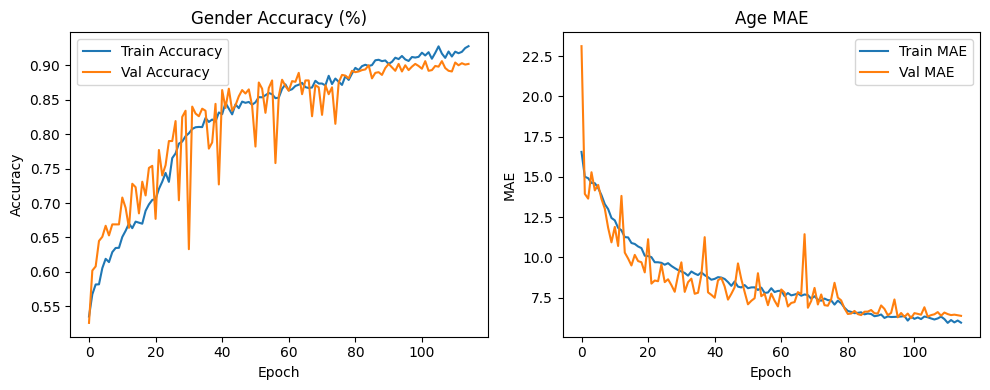

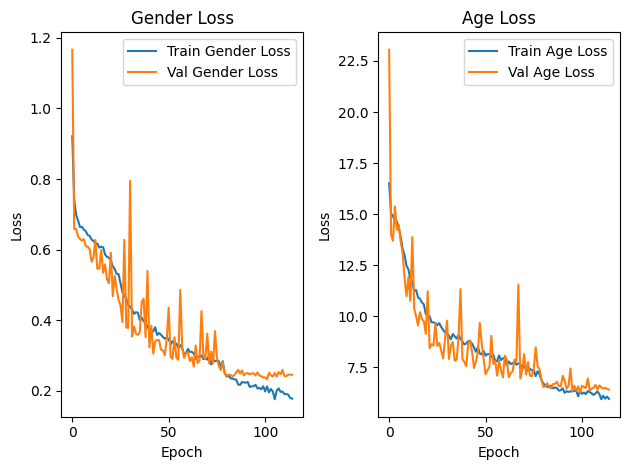

In [16]:
plt.figure(figsize=(10, 4))

# Gender Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['gender_output_accuracy'], label='Train Accuracy')
plt.plot(history.history['val_gender_output_accuracy'], label='Val Accuracy')
plt.title('Gender Accuracy (%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Age MAE
plt.subplot(1, 2, 2)
plt.plot(history.history['age_output_mae'], label='Train MAE')
plt.plot(history.history['val_age_output_mae'], label='Val MAE')
plt.title('Age MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()


plt.tight_layout()
plt.show()

# Gender Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['gender_output_loss'], label='Train Gender Loss')
plt.plot(history.history['val_gender_output_loss'], label='Val Gender Loss')
plt.title('Gender Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Age Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['age_output_loss'], label='Train Age Loss')
plt.plot(history.history['val_age_output_loss'], label='Val Age Loss')
plt.title('Age Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()



#modelB.summary()
#from tensorflow.keras.utils import plot_model
#plot_model(modelB, show_shapes=True,dpi=100)


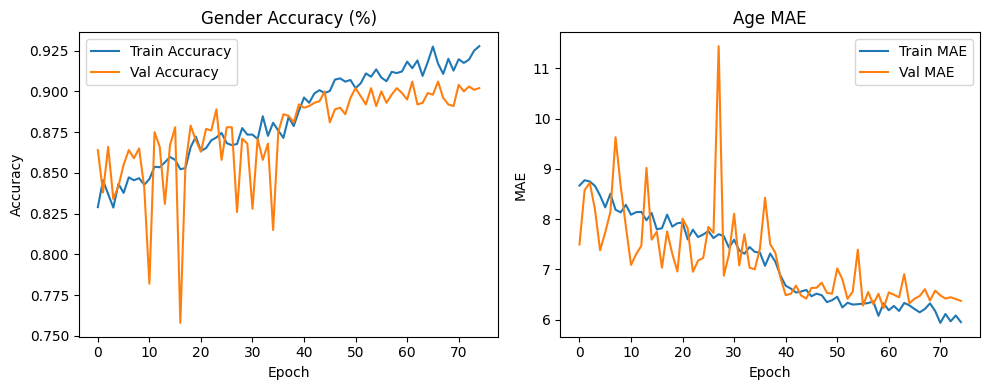

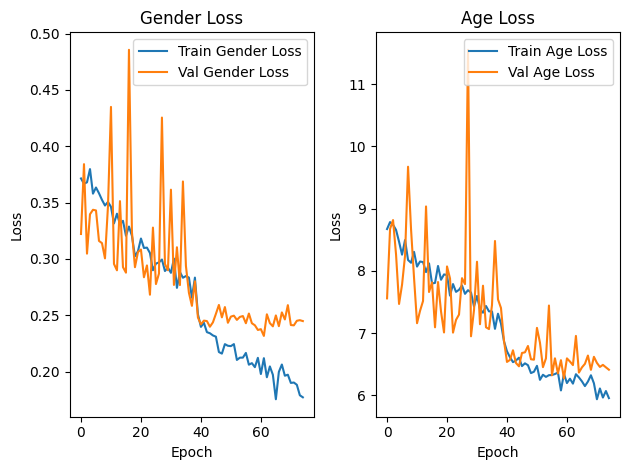

In [17]:
plt.figure(figsize=(10, 4))

start_epoch = 40
# Gender Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['gender_output_accuracy'][start_epoch:], label='Train Accuracy')
plt.plot(history.history['val_gender_output_accuracy'][start_epoch:], label='Val Accuracy')
plt.title('Gender Accuracy (%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Age MAE
plt.subplot(1, 2, 2)
plt.plot(history.history['age_output_mae'][start_epoch:], label='Train MAE')
plt.plot(history.history['val_age_output_mae'][start_epoch:], label='Val MAE')
plt.title('Age MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()


plt.tight_layout()
plt.show()

# Gender Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['gender_output_loss'][start_epoch:], label='Train Gender Loss')
plt.plot(history.history['val_gender_output_loss'][start_epoch:], label='Val Gender Loss')
plt.title('Gender Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Age Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['age_output_loss'][start_epoch:], label='Train Age Loss')
plt.plot(history.history['val_age_output_loss'][start_epoch:], label='Val Age Loss')
plt.title('Age Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## STEP2B: Build a CNN network based on a pre-trained model
Choose an existing CNN architecture pre-trained on ImageNet and fine-tune it on this dataset.

As with Model A, **do not resize the input image size**.
Ensure that the output layer for **the gender branch has only 1 unit**.

At the end of the cell, use `modelB.summary()` to display the model architecture and use `plot_model()` to visualize the architecture.


Fine-tuning started…
Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 139ms/step - age_output_loss: 31.0241 - age_output_mae: 31.0353 - gender_output_accuracy: 0.6950 - gender_output_loss: 0.6003 - loss: 32.3260 - val_age_output_loss: 30.0672 - val_age_output_mae: 29.9268 - val_gender_output_accuracy: 0.7840 - val_gender_output_loss: 0.4472 - val_loss: 31.0091 - learning_rate: 0.0010
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - age_output_loss: 26.7332 - age_output_mae: 26.7967 - gender_output_accuracy: 0.7377 - gender_output_loss: 0.5383 - loss: 27.9487 - val_age_output_loss: 25.3096 - val_age_output_mae: 25.1840 - val_gender_output_accuracy: 0.8060 - val_gender_output_loss: 0.4220 - val_loss: 26.2046 - learning_rate: 0.0010
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - age_output_loss: 21.8513 - age_output_mae: 21.8258 - gender_output_accuracy: 0.7467 - gender_output_loss: 0.5259 - loss: 22.9396 - val_age_output_loss: 22.2714 - val_age_output_mae: 22.1458 - val_gender_output_

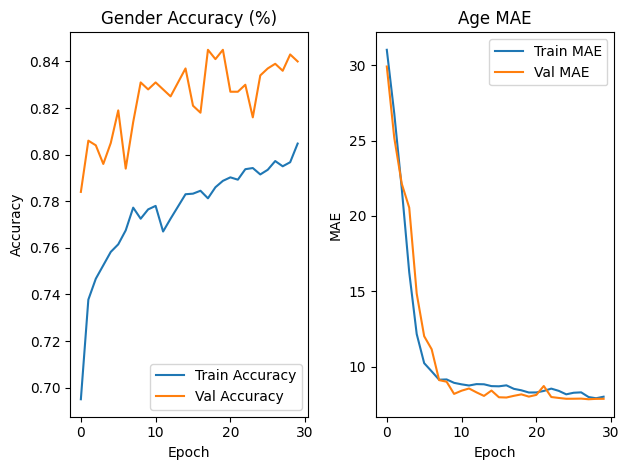

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ keras_tensor_1306C… │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 134, 134,  │          0 │ keras_tensor_130… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,472 │ conv1_pad[1][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 66, 66,    │          0 │ conv1_conv[1][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 32, 32,    │          0 │ pool1_pad[1][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 32, 32,    │        256 │ pool1_pool[1][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 32, 32,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 34, 34,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 32, 32,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 32, 32,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 32, 32,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 32, 32,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 32, 32,    │          0 │ conv2_block1_0_c

 Total params: 25,340,680 (96.67 MB)

 Trainable params: 591,618 (2.26 MB)

 Non-trainable params: 23,565,824 (89.90 MB)

 Optimizer params: 1,183,238 (4.51 MB)

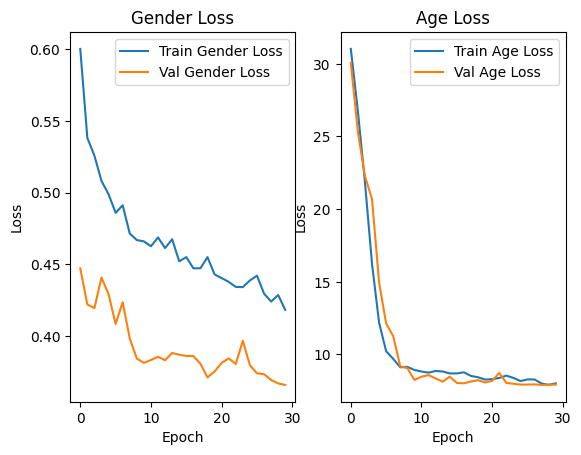

In [ ]:
#
# Add your code here
#
import matplotlib.pyplot as plt

from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, Activation
)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.optimizers import Adam

from tensorflow.keras.applications import ResNet152V2

from tensorflow.keras.applications import  MobileNetV2

from keras.models import Model, Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, BatchNormalization, Add, GlobalAveragePooling2D, SpatialDropout2D, Input,Dropout
from keras.utils import plot_model
from keras import layers
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

from keras.regularizers import l2



data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomShear(0.1),

      # --- Colour (subtle) ---

    layers.RandomHue(factor=0.02, value_range=[0, 1]),

    layers.RandomGrayscale(factor=0.02),    


layers.RandomGaussianBlur(factor=0.02)

])


input_tensor = Input(shape=(128, 128, 3))

input_tensor  = data_augmentation(input_tensor, training=True)






 


# Input


# Base model
base_model = ResNet50V2(weights='imagenet', include_top=False, input_tensor=input_tensor)
base_model.trainable = False  # freeze for warm-up

# Shared features
x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.4)(x)

shared = Dense(256, kernel_regularizer=l2(1e-3))(x)
shared = BatchNormalization()(shared)
shared = Activation("relu")(shared)
shared = Dropout(0.4)(shared)

# ===== Gender branch =====
g = Dense(128, kernel_regularizer=l2(1e-3))(shared)
g = BatchNormalization()(g)
g = Activation("relu")(g)
g = Dropout(0.3)(g)




gender_out = Dense(1,activation='sigmoid',kernel_regularizer=l2(0.001),name='gender_output')(g)

# ===== Age branch =====
a = Dense(128, kernel_regularizer=l2(1e-3))(shared)
a = BatchNormalization()(a)
a = Activation("relu")(a)
a = Dropout(0.3)(a)





age_out = Dense(1,activation='linear', kernel_regularizer=l2(0.001),name='age_output')(a)





# Model
modelB = Model(inputs=input_tensor, outputs=[gender_out, age_out])

print("Fine-tuning started…")
+
+

modelB.compile(
    optimizer="adam",
    loss={
        'gender_output': 'binary_crossentropy',
        'age_output': 'mae'
    },
     #loss_weights={'gender_output': 0.5, 'age_output': 1.0},
    metrics={
        'gender_output': 'accuracy',
        
        'age_output': 'mae'
    }
)


# --- Callbacks ---
es_callback = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,

    verbose=1
)




rlr_callback = ReduceLROnPlateau(
    monitor='val_loss',
    cooldown=5,
    factor=0.25,
    patience=7,  
    verbose=1,
    min_lr=1e-6
)


history_ft = modelB.fit(
    train_images,
    {'gender_output': train_gender, 'age_output': train_age},
    validation_data=(val_images, {'gender_output': val_gender, 'age_output': val_age}),
    epochs=30,
    batch_size=64,
    callbacks=[ rlr_callback]
)

start_epoch=0
plt.subplot(1, 2, 1)
plt.plot(history_ft.history['gender_output_accuracy'][start_epoch:], label='Train Accuracy')
plt.plot(history_ft.history['val_gender_output_accuracy'][start_epoch:], label='Val Accuracy')
plt.title('Gender Accuracy (%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Age MAE
plt.subplot(1, 2, 2)
plt.plot(history_ft.history['age_output_mae'][start_epoch:], label='Train MAE')
plt.plot(history_ft.history['val_age_output_mae'][start_epoch:], label='Val MAE')
plt.title('Age MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()


plt.tight_layout()
plt.show()

# Gender Loss
plt.subplot(1, 2, 1)
plt.plot(history_ft.history['gender_output_loss'][start_epoch:], label='Train Gender Loss')
plt.plot(history_ft.history['val_gender_output_loss'][start_epoch:], label='Val Gender Loss')
plt.title('Gender Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Age Loss
plt.subplot(1, 2, 2)
plt.plot(history_ft.history['age_output_loss'][start_epoch:], label='Train Age Loss')
plt.plot(history_ft.history['val_age_output_loss'][start_epoch:], label='Val Age Loss')
plt.title('Age Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()




modelB.summary()


## STEP3B: Compile and train your model
Compile and train your model here.
Save your model to `age_gender_B.keras` after training.

**DON'T use any other name for your model file.** This is because my test code relies on this particular model name. Any other file name will cause problem in the testing stage.

**Also, save the model with `save()` instead of `save_weights()`.**


In [31]:
#
# Add your code here
#

import matplotlib.pyplot as plt
from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D, Dense, Dropout, BatchNormalization, Activation
)
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.optimizers import Adam

from tensorflow.keras.applications import ResNet152V2

from tensorflow.keras.applications import  MobileNetV2

from keras.models import Model, Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, BatchNormalization, Add, GlobalAveragePooling2D, SpatialDropout2D, Input,Dropout
from keras.utils import plot_model
from keras import layers
from keras.regularizers import l2







print("STAGE 2: Unfreezing top of ResNet50V2...")

# Unfreeze LAST 60 layers of ResNet50V2
for layer in base_model.layers[-50:]:
    layer.trainable = True

# Recompile with tiny LR
modelB.compile(
    optimizer="adam",
    loss={'gender_output': 'binary_crossentropy', 'age_output': 'mae'},
    metrics={'gender_output': 'accuracy', 'age_output': 'mae'}
)

history_stage2 = modelB.fit(
    train_images,
    {'gender_output': train_gender, 'age_output': train_age},
    validation_data=(val_images, {'gender_output': val_gender, 'age_output': val_age}),
    epochs=45,
    batch_size=64,
    callbacks=[es_callback, rlr_callback]
)

print("Fine-tuning complete.")



# Plot training history



es_callback = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,

    verbose=1
)




modelB.save("age_gender_B.keras")

STAGE 2: Unfreezing top of ResNet50V2...
Epoch 1/45
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 193ms/step - age_output_loss: 8.9059 - age_output_mae: 8.9177 - gender_output_accuracy: 0.7310 - gender_output_loss: 0.5407 - loss: 10.2550 - val_age_output_loss: 11.1916 - val_age_output_mae: 11.0673 - val_gender_output_accuracy: 0.5420 - val_gender_output_loss: 1.5023 - val_loss: 13.3431 - learning_rate: 0.0010
Epoch 2/45
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - age_output_loss: 7.2012 - age_output_mae: 7.2028 - gender_output_accuracy: 0.7912 - gender_output_loss: 0.4408 - loss: 8.4114 - val_age_output_loss: 7.9817 - val_age_output_mae: 7.9225 - val_gender_output_accuracy: 0.7400 - val_gender_output_loss: 0.5753 - val_loss: 9.2414 - learning_rate: 0.0010
Epoch 3/45
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - age_output_loss: 6.5515 - age_output_mae: 6.5331 - gender_output_accuracy: 0.8375 - gender_output_loss: 0.3542 - loss: 7.6192 - val_age_output_loss: 6.9437 - val_age_output_mae: 6.8717 - val_gender_

## STEP4B: Draw the learning curves
Draw four learning curve figures for model B as follows.
1. The loss of the gender classification over the training and validation set
2. The accuracy of the gender classification over the training and validation set
3. The loss of the age estimation over the training and validation set
4. The MAE of the age estimation over the training and validation set

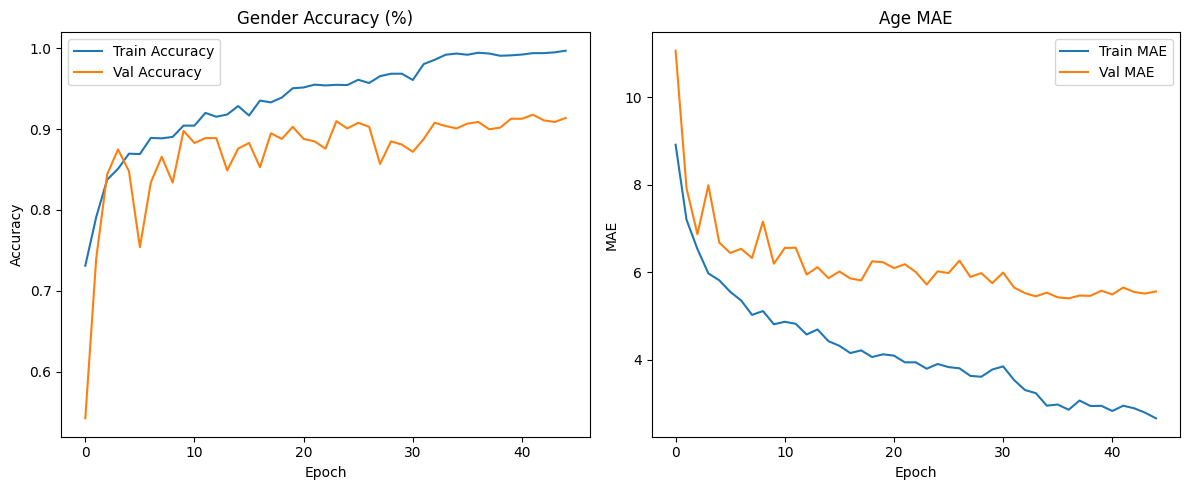

In [35]:
#
# Add your code here

#
import matplotlib.pyplot as plt


plt.figure(figsize=(12, 5))

# Gender accuracy
plt.subplot(1, 2, 1)
plt.plot(history_stage2.history['gender_output_accuracy'], label='Train Accuracy')
plt.plot(history_stage2.history['val_gender_output_accuracy'], label='Val Accuracy')
plt.title('Gender Accuracy (%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Age MAE
plt.subplot(1, 2, 2)
plt.plot(history_stage2.history['age_output_mae'], label='Train MAE')
plt.plot(history_stage2.history['val_age_output_mae'], label='Val MAE')
plt.title('Age MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()


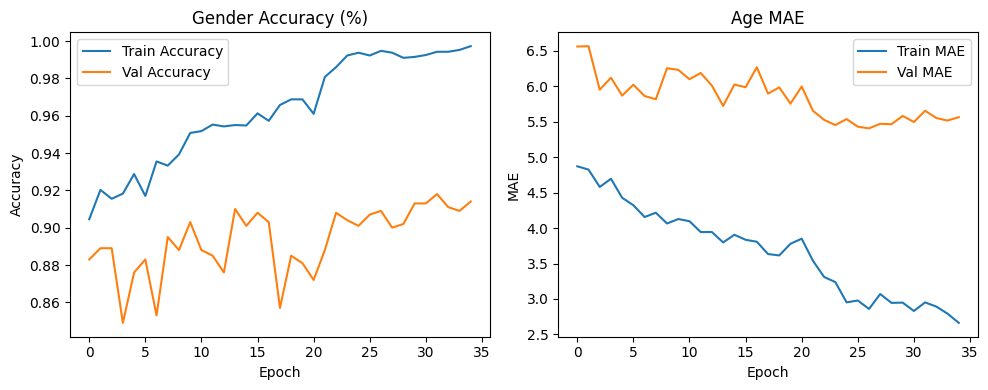

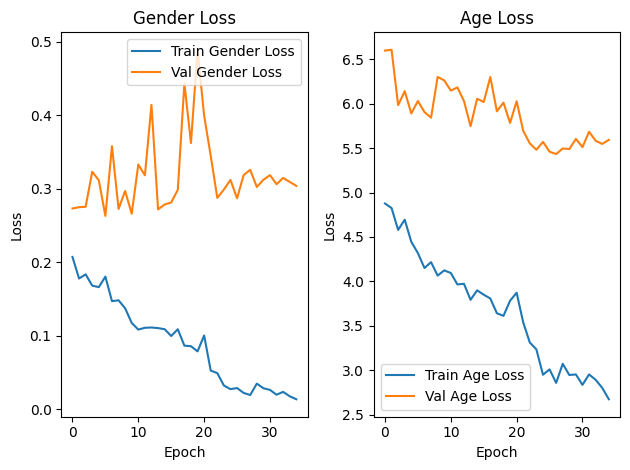

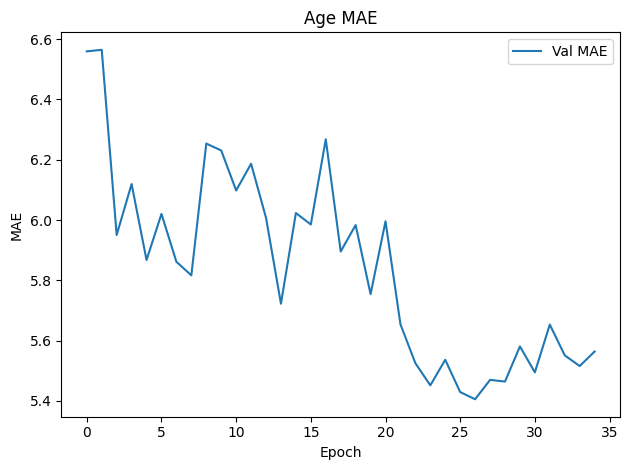

In [36]:

#
# Add your code here
#

import matplotlib.pyplot as plt

start_epoch=10


plt.figure(figsize=(10, 4))

# Gender Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_stage2.history['gender_output_accuracy'][start_epoch:], label='Train Accuracy')
plt.plot(history_stage2.history['val_gender_output_accuracy'][start_epoch:], label='Val Accuracy')
plt.title('Gender Accuracy (%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Age MAE
plt.subplot(1, 2, 2)
plt.plot(history_stage2.history['age_output_mae'][start_epoch:], label='Train MAE')
plt.plot(history_stage2.history['val_age_output_mae'][start_epoch:], label='Val MAE')
plt.title('Age MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()


plt.tight_layout()
plt.show()

# Gender Loss
plt.subplot(1, 2, 1)
plt.plot(history_stage2.history['gender_output_loss'][start_epoch:], label='Train Gender Loss')
plt.plot(history_stage2.history['val_gender_output_loss'][start_epoch:], label='Val Gender Loss')
plt.title('Gender Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Age Loss
plt.subplot(1, 2, 2)
plt.plot(history_stage2.history['age_output_loss'][start_epoch:], label='Train Age Loss')
plt.plot(history_stage2.history['val_age_output_loss'][start_epoch:], label='Val Age Loss')
plt.title('Age Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()



# Age MAE
plt.subplot(1, 1, 1)

plt.plot(history_stage2.history['val_age_output_mae'][start_epoch:], label='Val MAE')
plt.title('Age MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()


plt.tight_layout()
plt.show()


## STEP5: Evaluate the model on the test set
I will load your two models for testing. The test set will not be available before your submission.

The metrics for measuring the performance on the test set are:
- age estimation: MAE (Mean Absolute Error)
- gender classification: accuracy


In [ ]:
#
# Don't add code in this cell when submitting this file
#